# EPB Detection System — Aplicação, Explicabilidade e Análise Temporal (V5)

Este notebook de aplicação usa **exclusivamente** a API do script V5
(`epb_detection_system_v5.py`) para reproduzir os artefactos de figura do artigo
`waimlap2026`. Ele segue os mesmos padrões do notebook principal V5
(`epb_detection_system_v5.ipynb`): as mesmas constantes, o mesmo pré-processamento e
QC, e o mesmo modo de obter o modelo — **treino em memória por leave-one-night-out +
`fit`**, sem carregar nenhum `.pkl`.

Quatro famílias de figuras (os sete nomes do artigo em `FIGS_DIR`):

1. **Erro de reconstrução 2DPCA** (`recon_error_without.png`, `recon_error_with.png`) —
   o que o subespaço 2DPCA não capta.
2. **Atribuição linear exata** (`shap_analysis_without.png`, `shap_analysis_with.png`) —
   o que o classificador linear usa para decidir (vermelho = evidência de EPB).
3. **Sequências temporais noturnas** (`temporal_without_epb.png`,
   `temporal_with_epb.png`, `temporal_cloudy_qc.png`) — evolução de P(EPB) por quadro,
   com a camada de confiabilidade em 3 vias (EPB / Sem EPB / Indeterminado).

Figuras adicionais que o V5 permite e o V4 não tinha:
`preprocessing_comparison.png` (comparação de pré-processamento V4→V5) e
`band_orientation.png` (orientação de banda por estação). E uma tabela-resumo de
verdito em 3 vias por noite (só impressa).

**Convenção das pastas `util/`**: cada pasta é uma noite identificada pela **data de
início** da observação; os quadros podem ter a data UTC do dia seguinte (a noite
atravessa a meia-noite).

**O modelo é construído em memória por leave-one-night-out** (como o notebook principal
V5), não carregado de um pkl. O notebook **não** regrava `models/epb_recognition_model-v5.0.pkl`
nem escreve em `test_evaluations.log`.


In [1]:
import os
import logging

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import epb_detection_system_v5 as v5
from epb_detection_system_v2 import extract_night_groups, setup_logging

setup_logging(logging.WARNING)
np.random.seed(42)

DATA_FOLDER = "data/all-images"
LABEL_FILE  = "data/epb_labels.csv"
TARGET_SIZE = (64, 64)
PARAM_GRID  = {"n_components": [3, 5, 10], "C": [0.001, 0.01, 0.1]}
FIGS_DIR    = "../waimlap2026/epb/figs"
os.makedirs(FIGS_DIR, exist_ok=True)

# Dados (512 px) e noites de observação — Estágio 2 (céu limpo)
raw, y, df_labels = v5.load_raw_dataset(DATA_FOLDER, LABEL_FILE)
nights = extract_night_groups(df_labels)
sites  = df_labels["site"].values

# Pré-processamento V5 + orientação por estação (igual ao notebook principal V5)
X_v5 = v5.preprocess_batch(raw, target_size=TARGET_SIZE, **v5.V5_PREPROCESS)
df_orient = v5.check_station_orientation(X_v5, y, sites, verbose=False)
needs = df_orient[df_orient["status"].str.startswith("tilted")]
ROTATION_BY_SITE = {r.station: -r.band_angle_deg for r in needs.itertuples()}
if ROTATION_BY_SITE:
    X_v5 = v5.preprocess_batch(raw, sites=sites, rotation_by_site=ROTATION_BY_SITE,
                               target_size=TARGET_SIZE, **v5.V5_PREPROCESS)

# Seleção de hiperparâmetros por leave-one-night-out e modelo final em memória
best_all, _ = v5.select_params_logo(
    X_v5, y, nights, PARAM_GRID, lambda **kw: v5.EPBRecognitionSystemV5(**kw))
final = v5.EPBRecognitionSystemV5(rotation_by_site=ROTATION_BY_SITE,
                                  target_size=TARGET_SIZE, **best_all)
final.fit(X_v5, y)
print(f"Parâmetros finais: {best_all} | conjunto de fundo X_v5: {X_v5.shape}")
print(f"ROTATION_BY_SITE: {ROTATION_BY_SITE}")


Parâmetros finais: {'C': 0.001, 'n_components': 5} | conjunto de fundo X_v5: (510, 64, 64)
ROTATION_BY_SITE: {}


In [2]:
from pathlib import Path


def _plot_recon_error(system, X_sample, raw, title, save_path, dpi=300):
    """Mapa de erro de reconstrução 2DPCA: bruta | entrada V5 | |entrada - reconstrução|."""
    proj  = system.tdpca.transform(X_sample[np.newaxis])      # (1, H, n_comp)
    recon = system.tdpca.inverse_transform(proj)[0]           # (H, W)
    err   = np.abs(X_sample - recon)                          # resíduo por pixel
    mask  = v5.fov_mask(X_sample.shape)                       # domo all-sky
    err_m = np.where(mask, err, np.nan)                       # fora do domo = NaN
    vmax  = np.nanpercentile(err_m, 99) or 1e-9
    fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
    ax[0].imshow(raw, cmap='gray')
    ax[0].set_title('Imagem bruta')
    ax[1].imshow(X_sample, cmap='RdBu_r', vmin=-3, vmax=3)
    ax[1].set_title('Entrada V5 (δI/I z-score)')
    im = ax[2].imshow(err_m, cmap='magma', vmin=0, vmax=vmax)
    ax[2].set_title('|entrada − reconstrução 2DPCA| (erro de reconstrução)')
    plt.colorbar(im, ax=ax[2], fraction=0.046)
    for a in ax:
        a.axis('off')
    fig.suptitle(title, fontsize=12, fontweight='bold')
    plt.tight_layout()
    Path(save_path).parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(save_path, dpi=dpi, bbox_inches='tight')
    print(f"💾 Figura gravada: {save_path}")
    return fig


In [3]:
import re


def _plot_temporal(frames_df, title, save_path, show_cloudy=False,
                   thumbnail_interval=10, image_folder=None, dpi=300):
    """Série temporal de P(EPB) por quadro, com camada de confiabilidade em 3 vias.

    frames_df: saída de `final.analyze_folder(folder)` (uma linha por quadro,
    já ordenada cronologicamente por nome de ficheiro). A figura tem o painel
    principal (probabilidade + estados), a barra de timeline e, se `image_folder`
    for passado, um painel de miniaturas (ax3) na MESMA figura.
    """
    if frames_df.empty:
        raise ValueError(f"sem quadros em {image_folder or save_path}")

    df = frames_df.reset_index(drop=True)
    n = len(df)

    # Eixo x: tempo UT se todos os nomes casarem o padrão; senão índice do quadro.
    times, ok_all = [], True
    for name in df['filename']:
        m = re.search(r'(\d{8})_(\d{6})', str(name))
        if m:
            times.append(pd.to_datetime(m.group(1) + m.group(2), format='%Y%m%d%H%M%S'))
        else:
            ok_all = False
            break
    if ok_all:
        x = np.array(times)
        x_num = np.arange(n)  # posições uniformes para a barra de timeline
    else:
        x = np.arange(n)
        x_num = x

    prob = df['prob_epb'].to_numpy(dtype=float) * 100.0  # NaN nos Indeterminado
    verdict = df['verdict'].to_numpy()
    reliable = df['reliable'].to_numpy(dtype=bool)

    # state_code: 2 = Indeterminado, 1 = EPB, 0 = Sem EPB
    state_code = np.where(verdict == 'Indeterminado', 2,
                          np.where(verdict == 'EPB', 1, 0))

    # Regime de confiabilidade por quadro, para as faixas de fundo:
    #   2 = Indeterminado (nublado)     -> cinza
    #   1 = decidido mas reliable=False -> amarelo-ténue
    #   0 = decidido e reliable=True    -> sem sombra (branco)
    regime = np.where(state_code == 2, 2, np.where(~reliable, 1, 0))

    light = {'bg': 'white', 'line': '#1f5fbf', 'fill': '#cfe0f7', 'grid': '#dddddd',
             'epb': '#d62728', 'quiet': '#2ca02c', 'undet': '#888888',
             'degraded_band': '#fff3b0', 'cloudy_band': '#e6e6e6'}

    # Resolve e valida as miniaturas ANTES de desenhar (falha fatal visível).
    thumb_idx, thumbs = [], []
    if image_folder is not None:
        for i in range(0, n, max(thumbnail_interval, 1)):
            thumb_path = Path(image_folder) / df.loc[i, 'filename']
            if not thumb_path.exists():
                raise FileNotFoundError(thumb_path)
            thumb_idx.append(i)
            thumbs.append(np.array(Image.open(thumb_path).convert('L')))

    n_rows = 3 if image_folder is not None else 2
    height_ratios = [4, 0.4, 1.6] if n_rows == 3 else [4, 0.4]
    fig = plt.figure(figsize=(14, 6 if n_rows == 2 else 8), facecolor=light['bg'])
    gs = fig.add_gridspec(n_rows, 1, height_ratios=height_ratios, hspace=0.12)
    ax1 = fig.add_subplot(gs[0])
    ax2 = fig.add_subplot(gs[1], sharex=ax1 if ok_all else None)
    ax3 = fig.add_subplot(gs[2]) if n_rows == 3 else None
    for ax in (ax1, ax2):
        ax.set_facecolor(light['bg'])

    # Faixas de fundo da camada de confiabilidade (agrupa quadros consecutivos).
    def _spans(codes, target):
        i = 0
        while i < len(codes):
            if codes[i] == target:
                j = i
                while j + 1 < len(codes) and codes[j + 1] == target:
                    j += 1
                yield i, j
                i = j + 1
            else:
                i += 1

    def _edge(k, side):  # limites visuais de uma faixa centrada no índice k
        if ok_all:
            if side == 'lo':
                return x[k] if k == 0 else x[k] - (x[k] - x[k - 1]) / 2
            return x[k] if k == n - 1 else x[k] + (x[k + 1] - x[k]) / 2
        return k - 0.5 if side == 'lo' else k + 0.5

    for code, color in ((2, light['cloudy_band']), (1, light['degraded_band'])):
        for a, b in _spans(regime, code):
            ax1.axvspan(_edge(a, 'lo'), _edge(b, 'hi'), color=color, zorder=0)

    # Linha de probabilidade (mascara NaN dos Indeterminado).
    prob_masked = np.ma.masked_invalid(prob)
    ax1.plot(x, prob_masked, color=light['line'], lw=1.6, zorder=3)
    ax1.fill_between(x, 0, prob_masked, color=light['fill'], alpha=0.5, zorder=1)

    # Pontos coloridos por estado; não confiáveis com contorno distinto.
    palette = {0: light['quiet'], 1: light['epb'], 2: light['undet']}
    for code in (0, 1, 2):
        for rel in (True, False):
            sel = (state_code == code) & (reliable == rel)
            if not sel.any():
                continue
            xs = x[sel]
            if code == 2:  # Indeterminado: sem probabilidade, fixa no topo do painel
                ys = np.full(sel.sum(), 2.0)
            else:
                ys = prob[sel]
            ax1.scatter(xs, ys, s=28, c=palette[code], zorder=4,
                        edgecolors=('black' if not rel else 'none'),
                        linewidths=(1.0 if not rel else 0.0),
                        hatch=('///' if not rel else None))

    for thr in (50, 70, 90):
        ax1.axhline(thr, color=light['grid'], ls='--', lw=0.8, zorder=2)
    ax1.set_ylim(-2, 102)
    ax1.set_ylabel('P(EPB) (%)')
    ax1.grid(True, color=light['grid'], lw=0.5, alpha=0.6)
    ax1.set_title(title, fontsize=12, fontweight='bold')

    # Legenda (inclui a categoria nublada só se show_cloudy).
    from matplotlib.lines import Line2D
    from matplotlib.patches import Patch
    handles = [
        Line2D([0], [0], marker='o', color='w', markerfacecolor=light['epb'],
               markersize=8, label='EPB'),
        Line2D([0], [0], marker='o', color='w', markerfacecolor=light['quiet'],
               markersize=8, label='Sem EPB'),
        Line2D([0], [0], marker='o', color='w', markerfacecolor=light['undet'],
               markeredgecolor='black', markersize=8, label='Conferir (visibilidade parcial)'),
        Patch(facecolor=light['degraded_band'], label='Faixa pouco confiável (DEGRADED)'),
    ]
    if show_cloudy:
        handles.append(Line2D([0], [0], marker='s', color='w', markerfacecolor=light['undet'],
                              markersize=8, label='Indeterminado — céu nublado'))
        handles.append(Patch(facecolor=light['cloudy_band'], label='Faixa nublada (Indeterminado)'))
    ax1.legend(handles=handles, loc='upper right', fontsize=8, framealpha=0.9)

    # Painel de timeline: 1 célula por quadro, colorida por estado.
    bar_colors = np.array([palette[c] for c in state_code])
    ax2.bar(x_num, np.ones(n), width=1.0, color=bar_colors, align='center')
    degr = (state_code != 2) & (~reliable)
    if degr.any():
        ax2.scatter(x_num[degr], np.full(degr.sum(), 1.02), marker='|',
                    color='black', s=30)
    ax2.set_ylim(0, 1.05)
    ax2.set_yticks([])
    ax2.set_xlabel('Tempo (UT)' if ok_all else 'Índice do quadro')
    if not ok_all:
        ax2.set_xlim(-0.5, n - 0.5)

    # Painel de miniaturas (ax3), na mesma figura, só se image_folder for passado.
    if ax3 is not None:
        ax3.axis('off')
        k = len(thumbs)
        if k:
            sub = ax3.get_subplotspec().subgridspec(1, k, wspace=0.05)
            for j, (idx, im_arr) in enumerate(zip(thumb_idx, thumbs)):
                axt = fig.add_subplot(sub[0, j])
                axt.imshow(im_arr, cmap='gray')
                axt.set_title(str(df.loc[idx, 'filename'])[-10:-4], fontsize=7)
                axt.axis('off')

    Path(save_path).parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(save_path, dpi=dpi, bbox_inches='tight')
    print(f"💾 Figura gravada: {save_path}")
    return fig


## Verificação de orientação de banda por estação

Mostra, por estação, a inclinação dominante das faixas de EPB (`band_angle_deg`) com o
seu espalhamento circular (`circular_spread_deg`) e a banda de tolerância de ±25°
(dentro dela, a estação não precisa de `rotation_by_site`). Estações sem quadros de EPB
têm orientação não verificável e são anotadas em vez de desenhadas. Reutiliza o
`df_orient` já calculado na célula de construção do modelo.


station  epb_frames  band_angle_deg  circular_spread_deg  median_coherence                         status
    BJL           0             NaN                  NaN               NaN not verifiable (no EPB frames)
     CA         213             5.4                 20.9             0.625     consistent (near vertical)
     CP          42             0.5                  6.1             0.565     consistent (near vertical)


💾 Figura gravada: ../waimlap2026/epb/figs/band_orientation.png


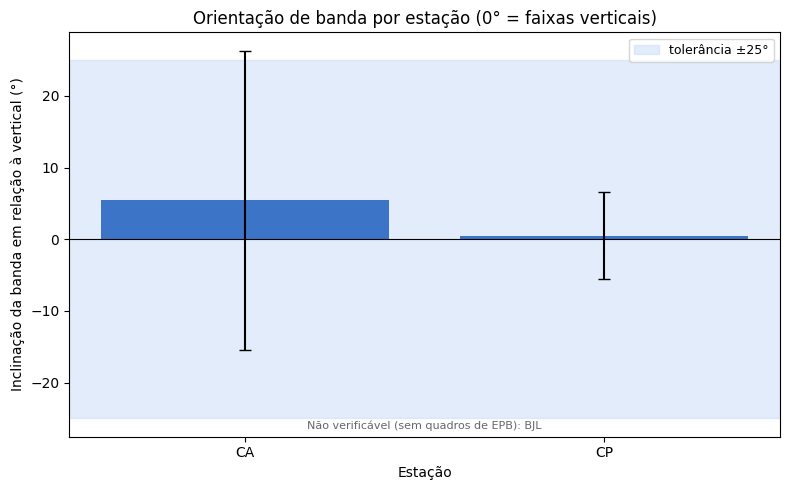

In [4]:
print(df_orient.to_string(index=False))

TOL_DEG = 25.0
known = df_orient.dropna(subset=["band_angle_deg"]).reset_index(drop=True)
missing = df_orient.loc[df_orient["band_angle_deg"].isna(), "station"].tolist()

fig, ax = plt.subplots(figsize=(8, 5))
ax.axhspan(-TOL_DEG, TOL_DEG, color="#cfe0f7", alpha=0.6,
           label=f"tolerância ±{TOL_DEG:.0f}°")
if len(known):
    ax.bar(known["station"], known["band_angle_deg"],
           yerr=known["circular_spread_deg"], capsize=4,
           color="#1f5fbf", alpha=0.85)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("Inclinação da banda em relação à vertical (°)")
ax.set_xlabel("Estação")
ax.set_title("Orientação de banda por estação (0° = faixas verticais)")
ax.legend(loc="upper right", fontsize=9)
if missing:
    ax.text(0.5, 0.02, "Não verificável (sem quadros de EPB): " + ", ".join(missing),
            transform=ax.transAxes, ha="center", fontsize=8, color="#666666")
plt.tight_layout()
from pathlib import Path
Path(FIGS_DIR).mkdir(parents=True, exist_ok=True)
fig.savefig(f"{FIGS_DIR}/band_orientation.png", dpi=300, bbox_inches="tight")
print(f"💾 Figura gravada: {FIGS_DIR}/band_orientation.png")
plt.show()


## Caso 1: ionosfera calma (SEM EPB) — cascata + erro de reconstrução + atribuição

Para a imagem calma da estação BJL, imprime o resultado da cascata (céu do Estágio 1,
status e P(EPB)) e grava duas figuras **distintas**: `recon_error_without.png` é o
**erro de reconstrução 2DPCA** (o que o subespaço não capta) e `shap_analysis_without.png`
é a **atribuição linear exata** (o que o classificador usa para decidir).


SEM EPB (img-teste/O6_BJL_20250723_003008.png) -> céu (Estágio 1): CLEAR
   • Status: Sem EPB | P(EPB): 12.54%


💾 Figura gravada: ../waimlap2026/epb/figs/recon_error_without.png


💾 Figure saved: ../waimlap2026/epb/figs/shap_analysis_without.png


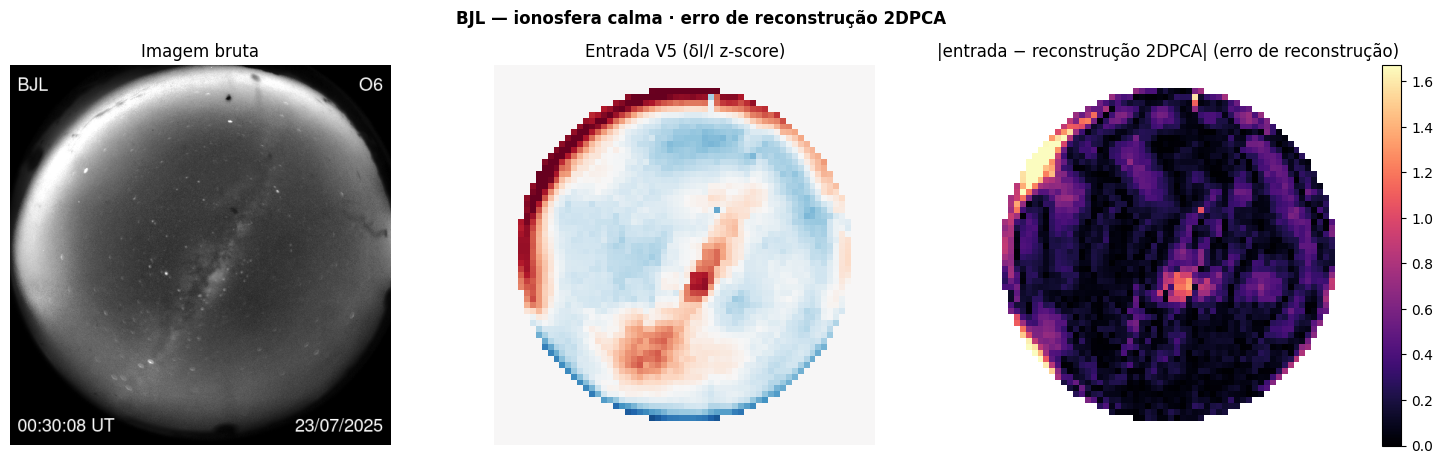

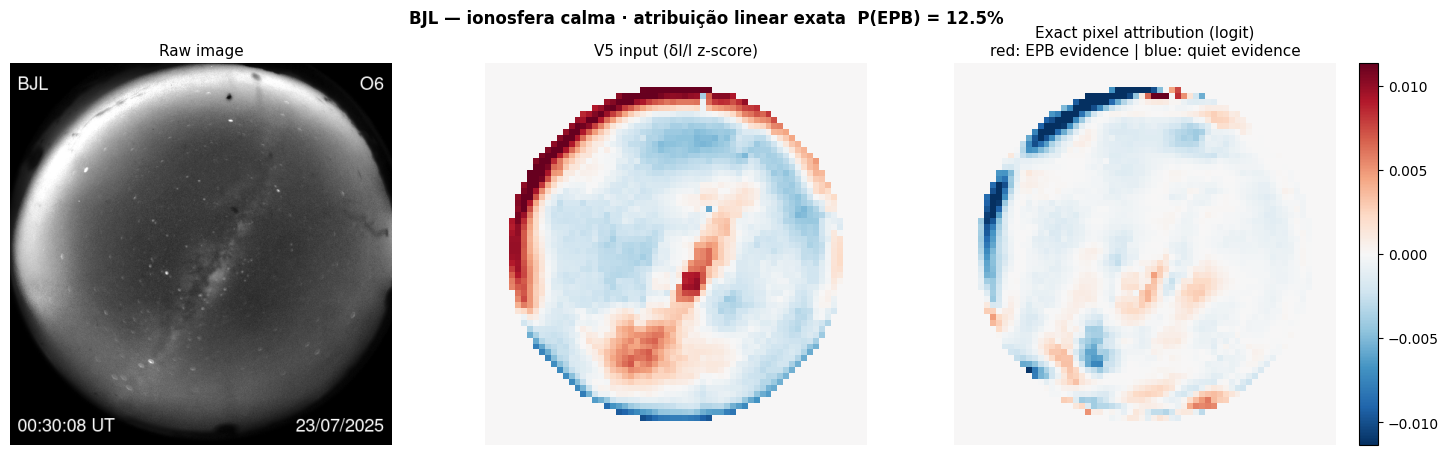

In [5]:
img_no_epb = "img-teste/O6_BJL_20250723_003008.png"
raw_no_epb = np.array(Image.open(img_no_epb).convert("L"))
res_no = final.predict_cascaded(raw_no_epb, qc_params=v5.QC_PARAMS)
print(f"SEM EPB ({img_no_epb}) -> céu (Estágio 1): {res_no.qc.condition}")
if res_no.prob_epb == res_no.prob_epb:  # não NaN
    print(f"   • Status: {res_no.status_label} | P(EPB): {res_no.prob_epb*100:.2f}%")
else:
    print(f"   • Status: {res_no.status_label} | P(EPB): indeterminada")

X_no = final.preprocess(raw_no_epb)
# recon_error_*: erro de reconstrução 2DPCA (vista distinta)
_plot_recon_error(final, X_no, raw_no_epb,
                  title="BJL — ionosfera calma · erro de reconstrução 2DPCA",
                  save_path=f"{FIGS_DIR}/recon_error_without.png", dpi=300)
# shap_analysis_*: atribuição linear exata (vista distinta)
v5.plot_linear_attribution(final, X_no, X_v5, raw=raw_no_epb,
                           title="BJL — ionosfera calma · atribuição linear exata",
                           save_path=f"{FIGS_DIR}/shap_analysis_without.png", dpi=300)
plt.show()


## Caso 2: evento de EPB ativo — cascata + erro de reconstrução + atribuição

Mesmo procedimento do Caso 1, agora para uma imagem com EPB ativa da estação CA,
gravando `recon_error_with.png` e `shap_analysis_with.png`.


COM EPB (img-teste/O6_CA_20251023_001620.png) -> céu (Estágio 1): CLEAR
   • Status: EPB detectada | P(EPB): 87.61%


💾 Figura gravada: ../waimlap2026/epb/figs/recon_error_with.png


💾 Figure saved: ../waimlap2026/epb/figs/shap_analysis_with.png


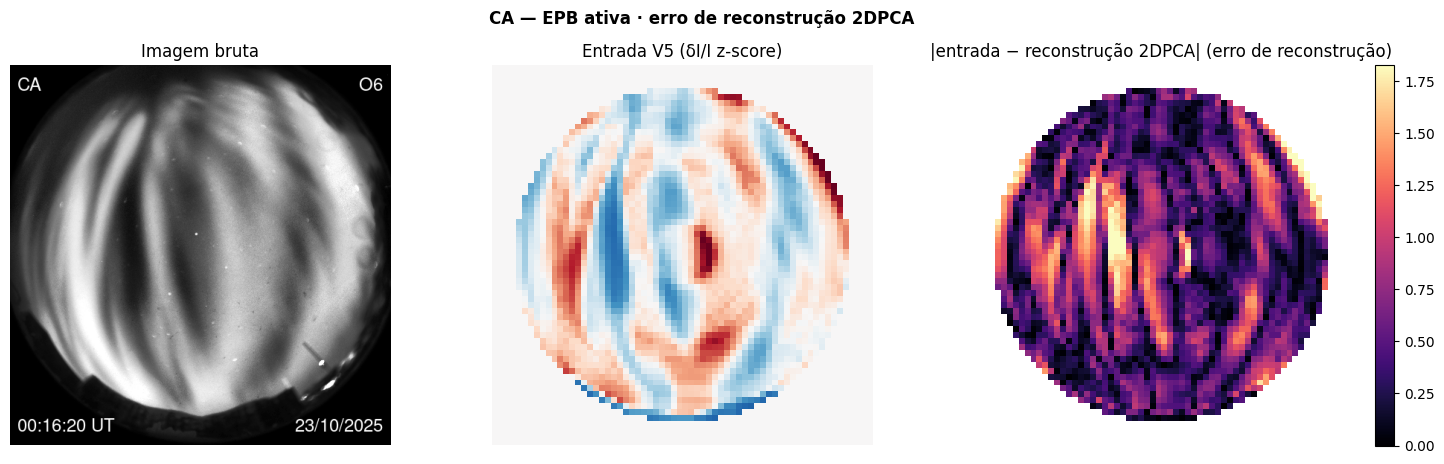

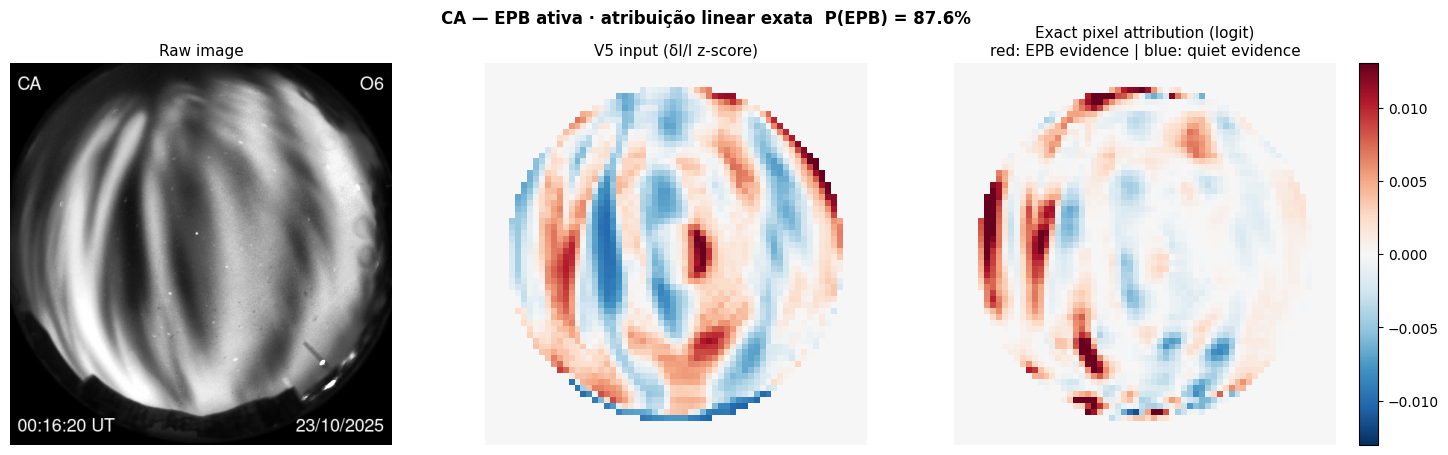

In [6]:
img_epb = "img-teste/O6_CA_20251023_001620.png"
raw_epb = np.array(Image.open(img_epb).convert("L"))
res_epb = final.predict_cascaded(raw_epb, qc_params=v5.QC_PARAMS)
print(f"COM EPB ({img_epb}) -> céu (Estágio 1): {res_epb.qc.condition}")
if res_epb.prob_epb == res_epb.prob_epb:  # não NaN
    print(f"   • Status: {res_epb.status_label} | P(EPB): {res_epb.prob_epb*100:.2f}%")
else:
    print(f"   • Status: {res_epb.status_label} | P(EPB): indeterminada")

X_epb = final.preprocess(raw_epb)
_plot_recon_error(final, X_epb, raw_epb,
                  title="CA — EPB ativa · erro de reconstrução 2DPCA",
                  save_path=f"{FIGS_DIR}/recon_error_with.png", dpi=300)
v5.plot_linear_attribution(final, X_epb, X_v5, raw=raw_epb,
                           title="CA — EPB ativa · atribuição linear exata",
                           save_path=f"{FIGS_DIR}/shap_analysis_with.png", dpi=300)
plt.show()


## Comparação de pré-processamento V4 → V5

Mostra, para os dois casos de teste (BJL calmo e CA com EPB), as etapas
`raw | V4 | V5 step | V5 δI/I z-score`. É a justificação visual de por que o V5 "vê"
depleções que o V4 cortava (o `clip(0)` do V4 elimina o sinal negativo da depleção).


💾 Figure saved: ../waimlap2026/epb/figs/preprocessing_comparison.png


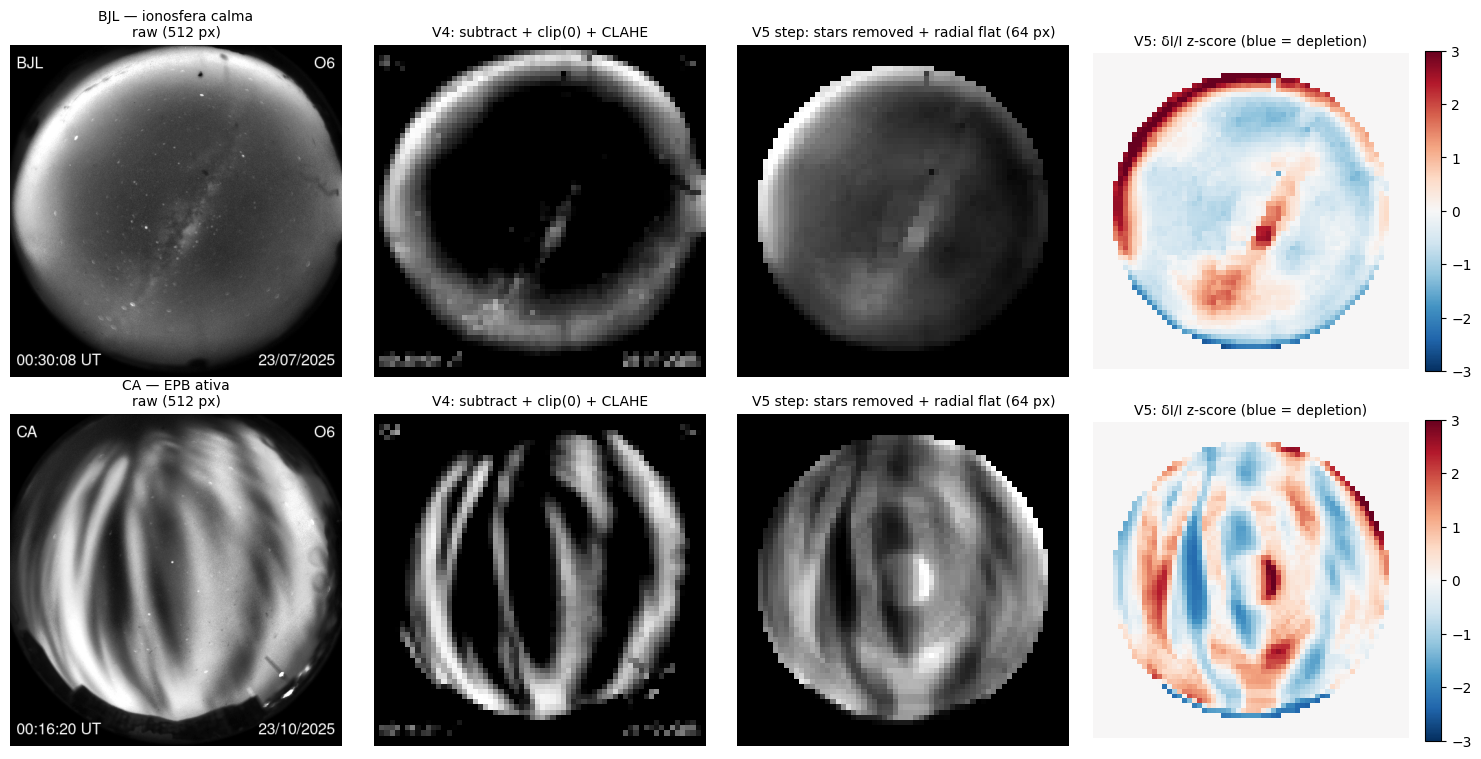

In [7]:
v5.plot_preprocessing_comparison(
    [("BJL — ionosfera calma", raw_no_epb), ("CA — EPB ativa", raw_epb)],
    target_size=TARGET_SIZE,
    save_path=f"{FIGS_DIR}/preprocessing_comparison.png", dpi=300)
plt.show()


## Sequências temporais noturnas (noite calma e noite com EPB)

A série de probabilidade por quadro vem de `final.analyze_folder`, que aplica o
pré-processamento V5 e o QC do Estágio 1 (cascata). A figura é montada por
`_plot_temporal`, que desenha a evolução de P(EPB), a timeline de estados por quadro, a
camada de confiabilidade em 3 vias e um painel de miniaturas.


 frames  EPB  Sem EPB  Indeterminado  conferir (visibilidade parcial)  cobertura_pct  epb_pct_dos_decididos
    230    0      222              8                                6           96.5                    0.0


💾 Figura gravada: ../waimlap2026/epb/figs/temporal_without_epb.png


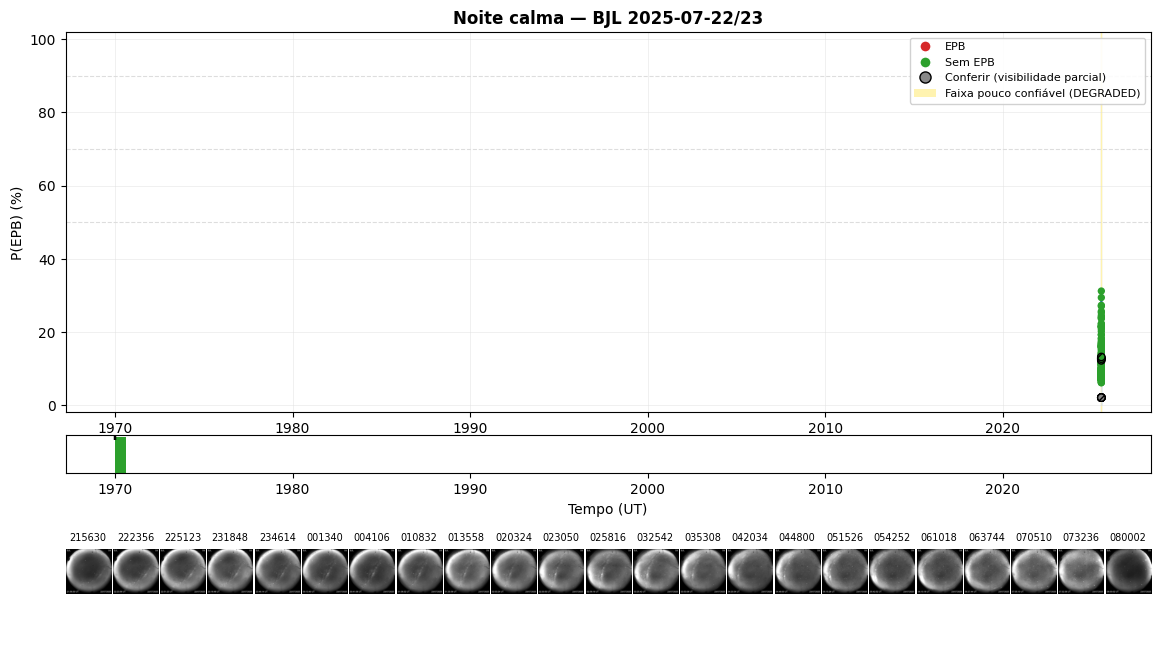

In [8]:
frames_bjl, resumo_bjl = final.analyze_folder("util/BJL_20250722/processed",
                                              qc_params=v5.QC_PARAMS)
print(resumo_bjl.to_string(index=False))
_plot_temporal(frames_bjl, title="Noite calma — BJL 2025-07-22/23",
               save_path=f"{FIGS_DIR}/temporal_without_epb.png",
               show_cloudy=False, thumbnail_interval=10,
               image_folder="util/BJL_20250722/processed", dpi=300)
plt.show()


 frames  EPB  Sem EPB  Indeterminado  conferir (visibilidade parcial)  cobertura_pct  epb_pct_dos_decididos
    140  138        0              2                                2           98.6                  100.0


💾 Figura gravada: ../waimlap2026/epb/figs/temporal_with_epb.png


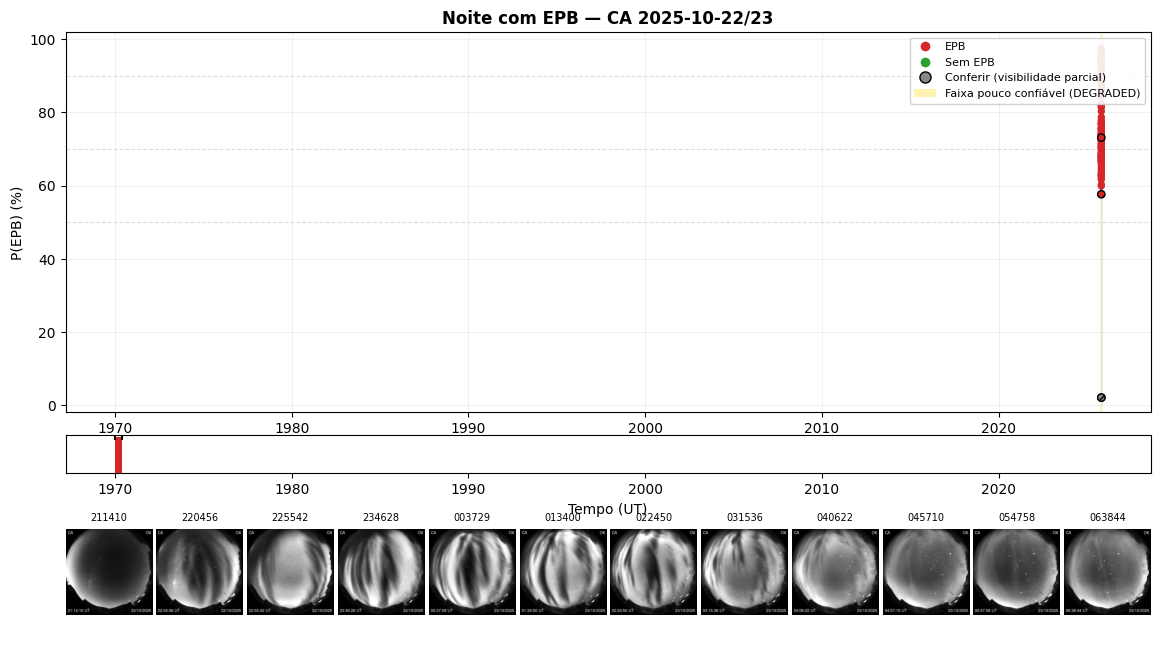

In [9]:
frames_ca, resumo_ca = final.analyze_folder("util/CA_20251022/processed",
                                            qc_params=v5.QC_PARAMS)
print(resumo_ca.to_string(index=False))
_plot_temporal(frames_ca, title="Noite com EPB — CA 2025-10-22/23",
               save_path=f"{FIGS_DIR}/temporal_with_epb.png",
               show_cloudy=False, thumbnail_interval=12,
               image_folder="util/CA_20251022/processed", dpi=300)
plt.show()


## Controlo de qualidade de nuvens em cascata (Estágio 1 + Estágio 2)

Na noite encoberta, o Estágio 1 marca os quadros nublados como `Indeterminado` (sem
decisão de EPB) e o Estágio 2 só decide nos quadros de céu válido. A figura distingue os
quadros indeterminados (cinza) dos decididos.


 frames  EPB  Sem EPB  Indeterminado  conferir (visibilidade parcial)  cobertura_pct  epb_pct_dos_decididos
     62   18       10             34                               15           45.2                   64.3


💾 Figura gravada: ../waimlap2026/epb/figs/temporal_cloudy_qc.png


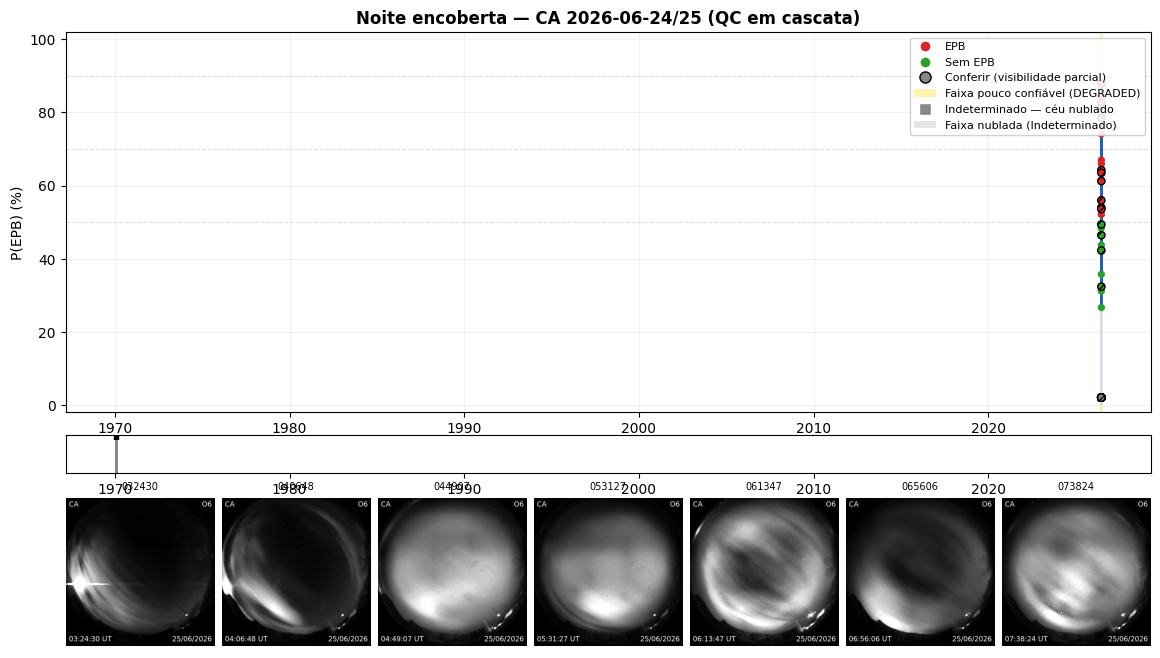

In [10]:
frames_cloudy, resumo_cloudy = final.analyze_folder("util/CA_20260624/processed",
                                                    qc_params=v5.QC_PARAMS)
print(resumo_cloudy.to_string(index=False))
_plot_temporal(frames_cloudy,
               title="Noite encoberta — CA 2026-06-24/25 (QC em cascata)",
               save_path=f"{FIGS_DIR}/temporal_cloudy_qc.png",
               show_cloudy=True, thumbnail_interval=10,
               image_folder="util/CA_20260624/processed", dpi=300)
plt.show()


## Tabela-resumo de verdito em 3 vias por noite

Concatena os três resumos por noite (`resumo_bjl`, `resumo_ca`, `resumo_cloudy`) já
obtidos acima, acrescenta a noite e uma coluna de **pior confiabilidade** derivada
(fração de quadros decididos marcados como "conferir"). Só impresso — sem escrita em
disco.


In [11]:
resumos = []
for noite, resumo in (("BJL 2025-07-22/23", resumo_bjl),
                      ("CA 2025-10-22/23", resumo_ca),
                      ("CA 2026-06-24/25", resumo_cloudy)):
    r = resumo.iloc[0].copy()
    decididos = int(r["frames"] - r["Indeterminado"])
    pior_conf = round(100 * r["conferir (visibilidade parcial)"] / max(decididos, 1), 1)
    linha = {"noite": noite, **r.to_dict(),
             "pior_confiabilidade_pct": pior_conf}
    resumos.append(linha)

resumo_por_noite = pd.DataFrame(resumos)
print(resumo_por_noite.to_string(index=False))


            noite  frames   EPB  Sem EPB  Indeterminado  conferir (visibilidade parcial)  cobertura_pct  epb_pct_dos_decididos  pior_confiabilidade_pct
BJL 2025-07-22/23   230.0   0.0    222.0            8.0                              6.0           96.5                    0.0                      2.7
 CA 2025-10-22/23   140.0 138.0      0.0            2.0                              2.0           98.6                  100.0                      1.4
 CA 2026-06-24/25    62.0  18.0     10.0           34.0                             15.0           45.2                   64.3                     53.6
